## 1. Extracting table containing dataset from pdf

In [ ]:
!pip install pymupdf -q
import pymupdf
import pandas as pd

pdf = pymupdf.open('/content/buildings-13-00255-v2.pdf')

start_page = 14
end_page = 18

print('Extracting data from pages 15 to 18')

Extracting data from pages 15 to 18


In [ ]:
!pip install pdfplumber -q
import pdfplumber
import pandas as pd

all_lines = []

with pdfplumber.open('/content/buildings-13-00255-v2.pdf') as pdf:

   # looping through pages 15 to 18 (index 14 to 17)

   for index in range(14, 18):

       page = pdf.pages[index]
       text = page.extract_text()

       if text:

          lines = text.split('\n')
          all_lines.extend(lines)


print(f'succesfully extracted {len(all_lines)} lines of text from pages 15-18!')

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
succesfully extracted 178 lines of text from pages 15-18!


In [ ]:
import pandas as pd
df = pd.DataFrame(all_lines, columns=['Raw_text'])
display(df.head(20))
print('\nMissing values check:')
print(df.isnull().sum())

,Raw_text
0,"Buildings2023,13,255 15of20"
1,AppendixA.DatasetofLateriticSoils
2,TableA1.Datasetoflateriticsoilsproperties.
3,MDD
4,S.No G(%) S(%) F(%) LL(%) PL(%) OMC(%) CBR(%)
5,(g/cc)
6,1 14 35 51 33 20 10.7 2.1 24
7,2 28 39 33 36 20 15.2 2.12 26
8,3 29 40 31 38 20 14.9 2.14 27
9,4 42 38 20 35 20 8.3 2.11 29



Missing values check:
Raw_text    0
dtype: int64


In [ ]:
df.duplicated()


,0
0,False
1,False
2,False
3,False
4,False
...,...
173,False
174,False
175,False
176,False


In [ ]:
df.describe()

,Raw_text
count,178
unique,167
top,(g/cc)
freq,4


In [ ]:
print(df.dtypes)
print(df.head(10))

Raw_text    object
dtype: object
                                        Raw_text
0                    Buildings2023,13,255 15of20
1              AppendixA.DatasetofLateriticSoils
2     TableA1.Datasetoflateriticsoilsproperties.
3                                            MDD
4  S.No G(%) S(%) F(%) LL(%) PL(%) OMC(%) CBR(%)
5                                         (g/cc)
6                   1 14 35 51 33 20 10.7 2.1 24
7                  2 28 39 33 36 20 15.2 2.12 26
8                  3 29 40 31 38 20 14.9 2.14 27
9                   4 42 38 20 35 20 8.3 2.11 29


In [ ]:
# filter out headers and metadata lines, then split rows into seperate columns
# (Adjust slicing based on where your actual table data starts and ends)
data_rows = all_lines[6:] # Example slice for data rows
parsed_data = [row.split() for row in data_rows if row.strip()]

# creating clean DataFrame with proper column names
columns = ["s.No", "G", "S", "F", "LL", "PL", "OMC", "MDD", "CBR"]
clean_df = pd.DataFrame(parsed_data, columns=columns)

# Convert columns to numeric types (float/int)
clean_df = clean_df.apply(pd.to_numeric, errors="coerce")
display(clean_df.head())


,s.No,G,S,F,LL,PL,OMC,MDD,CBR
0,1.0,14.0,35.0,51.0,33.0,20.0,10.7,2.10,24.0
1,2.0,28.0,39.0,33.0,36.0,20.0,15.2,2.12,26.0
2,3.0,29.0,40.0,31.0,38.0,20.0,14.9,2.14,27.0
3,4.0,42.0,38.0,20.0,35.0,20.0,8.3,2.11,29.0
4,5.0,39.0,32.0,29.0,36.0,20.0,9.3,2.16,28.0


In [ ]:
clean_df.isnull().sum()

,0
s.No,20
G,23
S,23
F,23
LL,23
PL,23
OMC,23
MDD,23
CBR,23


In [ ]:
print('dataset shape:', clean_df.shape)

print('\nColumn names:')
print(clean_df.columns.tolist())

print("\nData Types:")
print(clean_df.dtypes)

print('\nMissing values:')
print(clean_df.isnull().sum())


print('\First 5 samples:')
display(clean_df.head())

print('\nLast 5 samples:')
display(clean_df.tail())


dataset shape: (172, 9)

Column names:
['s.No', 'G', 'S', 'F', 'LL', 'PL', 'OMC', 'MDD', 'CBR']

Data Types:
s.No    float64
G       float64
S       float64
F       float64
LL      float64
PL      float64
OMC     float64
MDD     float64
CBR     float64
dtype: object

Missing values:
s.No    20
G       23
S       23
F       23
LL      23
PL      23
OMC     23
MDD     23
CBR     23
dtype: int64
\First 5 samples:


<>:13: SyntaxWarning: invalid escape sequence '\F'
<>:13: SyntaxWarning: invalid escape sequence '\F'
/tmp/ipykernel_542/3625631672.py:13: SyntaxWarning: invalid escape sequence '\F'
  print('\First 5 samples:')


,s.No,G,S,F,LL,PL,OMC,MDD,CBR
0,1.0,14.0,35.0,51.0,33.0,20.0,10.7,2.10,24.0
1,2.0,28.0,39.0,33.0,36.0,20.0,15.2,2.12,26.0
2,3.0,29.0,40.0,31.0,38.0,20.0,14.9,2.14,27.0
3,4.0,42.0,38.0,20.0,35.0,20.0,8.3,2.11,29.0
4,5.0,39.0,32.0,29.0,36.0,20.0,9.3,2.16,28.0



Last 5 samples:


,s.No,G,S,F,LL,PL,OMC,MDD,CBR
167,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
168,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
169,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
170,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
171,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# Keep only the rows belonging to actual soil samples (strictly indices 0 to 148 for 149 rows)
clean_df_final = clean_df.dropna(subset=['s.No']).copy()

# Filter out any stray numbers from the references by cutting off after row index 149
clean_df_final = clean_df_final.iloc[:149].reset_index(drop=True)

# Convert all property columns to numeric cleanly
columns = ["s.No", "G", "S", "F", "LL", "PL", "OMC", "MDD", "CBR"]
for col in columns:
    clean_df_final[col] = pd.to_numeric(clean_df_final[col], errors='coerce')

# Final Verification
print("Final dataset shape:", clean_df_final.shape)
display(clean_df_final.head(3))
display(clean_df_final.tail(3))

Final dataset shape: (149, 9)


,s.No,G,S,F,LL,PL,OMC,MDD,CBR
0,1.0,14.0,35.0,51.0,33.0,20.0,10.7,2.10,24.0
1,2.0,28.0,39.0,33.0,36.0,20.0,15.2,2.12,26.0
2,3.0,29.0,40.0,31.0,38.0,20.0,14.9,2.14,27.0


,s.No,G,S,F,LL,PL,OMC,MDD,CBR
146,147.0,28.0,50.0,32.0,39.0,22.0,16.80,2.14,25.0
147,148.0,2.0,24.0,74.0,45.0,24.0,22.05,2.06,16.0
148,149.0,1.0,69.0,30.0,24.0,18.0,18.00,2.00,23.0


In [ ]:
print("Dataset Dimensions:", clean_df_final.shape)

print("\nColumn Names:")
print(clean_df_final.columns.tolist())

print("\nMissing Values:")
print(clean_df_final.isnull().sum())

print("duplicated rows:")
print(clean_df_final.duplicated().sum())

print("\nData types:")
print(clean_df_final.dtypes)

display(clean_df_final.describe())


Dataset Dimensions: (149, 9)

Column Names:
['s.No', 'G', 'S', 'F', 'LL', 'PL', 'OMC', 'MDD', 'CBR']

Missing Values:
s.No    0
G       0
S       0
F       0
LL      0
PL      0
OMC     0
MDD     0
CBR     0
dtype: int64
duplicated rows:
0

Data types:
s.No    float64
G       float64
S       float64
F       float64
LL      float64
PL      float64
OMC     float64
MDD     float64
CBR     float64
dtype: object


,s.No,G,S,F,LL,PL,OMC,MDD,CBR
count,149.000000,149.000000,149.000000,149.000000,149.000000,149.000000,149.000000,149.000000,149.000000
mean,75.000000,22.651007,42.281879,35.208054,33.557047,19.338926,13.250738,2.079664,25.416107
std,43.156691,20.904198,16.423484,17.794349,11.231822,5.578151,4.647303,0.094836,4.944422
min,1.000000,0.000000,14.000000,8.000000,0.000000,0.000000,5.300000,1.870000,12.000000
25%,38.000000,0.000000,31.000000,21.000000,29.000000,19.000000,10.360000,2.010000,22.000000
50%,75.000000,24.000000,39.000000,31.000000,35.000000,20.000000,12.900000,2.100000,26.000000
75%,112.000000,41.000000,50.000000,51.000000,40.000000,22.000000,15.800000,2.160000,29.000000
max,149.000000,65.000000,88.000000,78.000000,68.000000,27.000000,30.700000,2.280000,34.000000


In [ ]:
# Creating a dedicated dataFrame for EDA/modeling without the serial number included
soil_df = clean_df_final.drop(columns=["s.No"])

# verifying the columns
print(soil_df.columns.tolist())

['G', 'S', 'F', 'LL', 'PL', 'OMC', 'MDD', 'CBR']


In [ ]:
import numpy as np

# Replace 0s with NaN for properties where 0 is physically impossible
cols_to_fix = ["G", "LL", "PL"]
soil_df[cols_to_fix] = soil_df[cols_to_fix].replace(0, np.nan)

# Now check how many missing values you have per column
print(soil_df.isnull().sum())


G      39
S       0
F       0
LL      8
PL     10
OMC     0
MDD     0
CBR     0
dtype: int64


In [ ]:
Q1 = soil_df.quantile(0.25)
Q3 = soil_df.quantile(0.75)
IQR = Q3 - Q1

# Define outlier bounds (standard 1.5 multiplier)
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Count outliers per column
outliers_count = ((soil_df < lower_bound) | (soil_df > upper_bound)).sum()
print("Outliers count per column (using IQR):")
print(outliers_count)

Outliers count per column (using IQR):
G       0
S      10
F       0
LL      3
PL      1
OMC     5
MDD     0
CBR     0
dtype: int64


In [ ]:
# Apply capping (Winsorizing) to handle outliers without dropping rows
for col in soil_df.columns:
    soil_df[col] = soil_df[col].clip(lower=lower_bound[col], upper=upper_bound[col])

print("Outliers successfully capped using the IQR method!")

Outliers successfully capped using the IQR method!


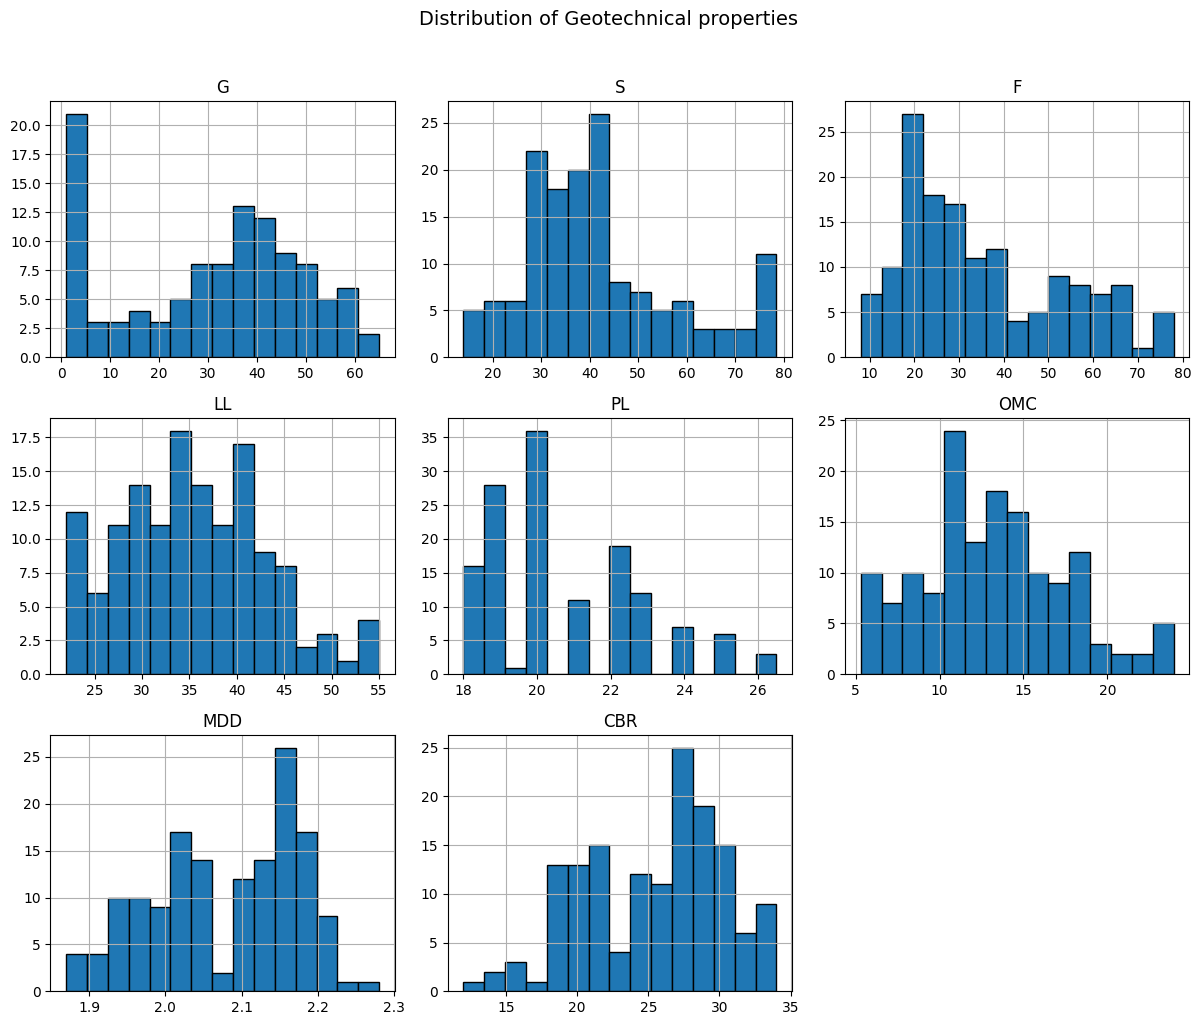

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

soil_df.hist(bins=15, figsize=(12, 10), edgecolor="black")
plt.suptitle("Distribution of Geotechnical properties", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()


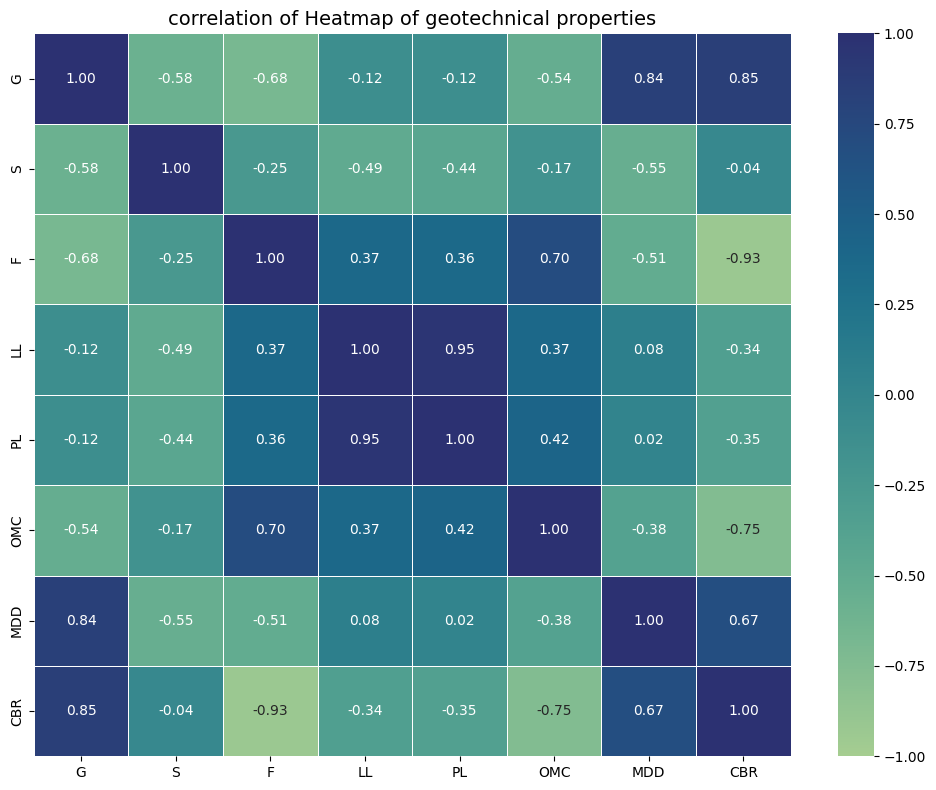

In [ ]:
# Matplotlib figure
plt.figure(figsize=(10, 8))

# setting up the correlation map
corr_style = soil_df.corr()

# Drawing the heatmap using seaborn
sns.heatmap(corr_style, annot=True, cmap="crest", fmt='.2f', linewidths=0.5, vmin=-1, vmax=1)

plt.title("correlation of Heatmap of geotechnical properties", fontsize=14)
plt.tight_layout()
plt.show()


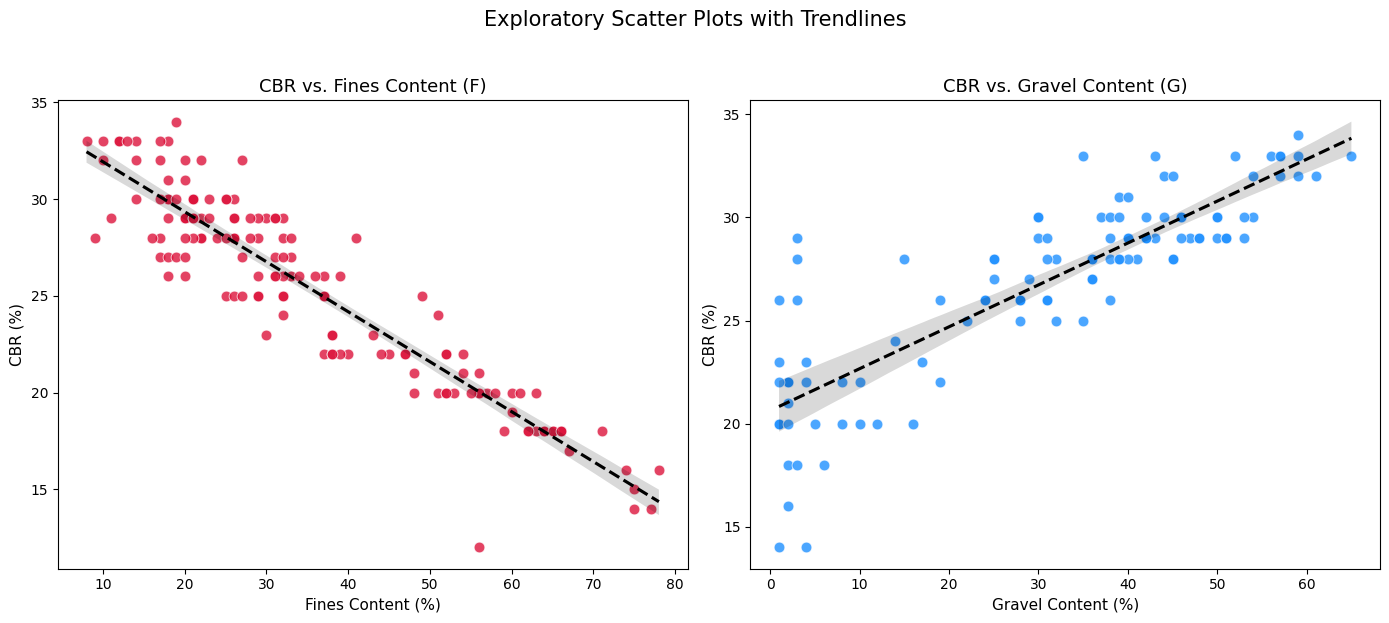

In [ ]:
# Create a figure with subplots for key relationships against CBR
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot 1: Fines Content vs CBR
sns.scatterplot(data=soil_df, x='F', y='CBR', ax=axes[0], color='crimson', s=60, alpha=0.8)
sns.regplot(data=soil_df, x='F', y='CBR', ax=axes[0], scatter=False, color='black', line_kws={'linestyle':'--'})
axes[0].set_title('CBR vs. Fines Content (F)', fontsize=13)
axes[0].set_xlabel('Fines Content (%)', fontsize=11)
axes[0].set_ylabel('CBR (%)', fontsize=11)

# Plot 2: Gravel Content vs CBR
sns.scatterplot(data=soil_df, x='G', y='CBR', ax=axes[1], color='dodgerblue', s=60, alpha=0.8)
sns.regplot(data=soil_df, x='G', y='CBR', ax=axes[1], scatter=False, color='black', line_kws={'linestyle':'--'})
axes[1].set_title('CBR vs. Gravel Content (G)', fontsize=13)
axes[1].set_xlabel('Gravel Content (%)', fontsize=11)
axes[1].set_ylabel('CBR (%)', fontsize=11)

plt.suptitle('Exploratory Scatter Plots with Trendlines', y=1.03, fontsize=15)
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# 1. Separate Features (X) and Target (y)
X = soil_df.drop(columns=['CBR'])
y = soil_df['CBR']

# 2. Impute missing values (using Median to handle the NaNs in G, LL, PL)
imputer = SimpleImputer(strategy='median')
X_imputed = pd.DataFrame(imputer.fit_transform(X), columns=X.columns)

# 3. Feature Scaling (Standardizing features for models that require it)
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X_imputed), columns=X.columns)

# 4. Train-Test Split (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# 5. Verification
print("Preprocessing Complete!")
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape:  {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape:  {y_test.shape}")

display(X_train.head(10))

Preprocessing Complete!
X_train shape: (119, 7)
X_test shape:  (30, 7)
y_train shape: (119,)
y_test shape:  (30,)


,G,S,F,LL,PL,OMC,MDD
22,0.440521,0.062800,-0.970313,-0.987926,-0.839605,-0.503574,1.273165
15,-1.806703,2.322517,-1.477798,-0.039990,-0.339200,0.230994,-1.689269
65,0.253253,-0.255470,-0.519216,0.637108,0.661609,-0.102690,0.849960
11,-0.433399,0.572032,-0.631990,-0.310829,-0.339200,-0.420153,0.215153
42,0.222041,0.253762,1.059624,-0.039990,-0.339200,-0.589312,-0.419654
105,-0.620668,-0.064508,0.101043,0.366269,0.661609,0.251849,0.638357
51,-0.807937,0.635686,-0.350054,-0.039990,-0.339200,-0.955437,0.426755
27,0.315676,-0.000854,-0.801152,-0.987926,-0.839605,-0.586994,0.426755
4,0.440521,-0.637395,-0.350054,0.095430,-0.339200,-0.890554,0.849960
32,0.222041,0.699340,0.664914,-0.310829,-0.339200,0.393201,0.003550


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 1. Initialize the 3 Models
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42)
}

# 2. Train and Evaluate each model
results = {}

for name, model in models.items():
    # Train the model on the training data
    model.fit(X_train, y_train)

    # Make predictions on the test set
    y_pred = model.predict(X_test)

    # Calculate evaluation metrics
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    # Store the results
    results[name] = {"RMSE": rmse, "MAE": mae, "R2 Score": r2}

# 3. Display the comparison table
results_df = pd.DataFrame(results).T
print("--- Model Performance Comparison ---")
display(results_df)

--- Model Performance Comparison ---


,RMSE,MAE,R2 Score
Linear Regression,0.676206,0.518521,0.981308
Random Forest,1.351106,1.096667,0.925375
Gradient Boosting,1.219791,0.955161,0.939176


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold, cross_val_score

# Define the full pipeline for Linear Regression (Imputer -> Scaler -> Model)
pipeline_lr = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('model', LinearRegression())
])

# Set up 5-Fold Cross Validation
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# Evaluate using R2 score across the 5 folds
cv_r2_scores = cross_val_score(pipeline_lr, X, y, cv=kf, scoring='r2')
# Evaluate using Root Mean Squared Error (RMSE) across the 5 folds
cv_rmse_scores = np.sqrt(-cross_val_score(pipeline_lr, X, y, cv=kf, scoring='neg_mean_squared_error'))

print("--- 5-Fold Cross-Validation Results for Linear Regression ---")
print(f"R² Scores per fold: {cv_r2_scores}")
print(f"Mean R² Score: {cv_r2_scores.mean():.4f} (± {cv_r2_scores.std():.4f})")
print(f"Mean RMSE: {cv_rmse_scores.mean():.4f} (± {cv_rmse_scores.std():.4f})")

--- 5-Fold Cross-Validation Results for Linear Regression ---
R² Scores per fold: [0.98103101 0.9752621  0.98153807 0.9738147  0.94685988]
Mean R² Score: 0.9717 (± 0.0128)
Mean RMSE: 0.8082 (± 0.2469)


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold, cross_val_score

# 1. Define your dictionary of models with pipelines to prevent data leakage
cv_models = {
    "Linear Regression": Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', LinearRegression())
    ]),
    "Random Forest": Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', RandomForestRegressor(random_state=42))
    ]),
    "Gradient Boosting": Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', GradientBoostingRegressor(random_state=42))
    ])
}

# 2. Set up 5-Fold Cross Validation
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# 3. Loop through each model and evaluate
cv_results = {}
for name, pipeline in cv_models.items():
    # Calculate R² and RMSE across folds
    r2_scores = cross_val_score(pipeline, X, y, cv=kf, scoring='r2')
    rmse_scores = np.sqrt(-cross_val_score(pipeline, X, y, cv=kf, scoring='neg_mean_squared_error'))

    cv_results[name] = {
        "Mean R²": r2_scores.mean(),
        "Std R²": r2_scores.std(),
        "Mean RMSE": rmse_scores.mean(),
        "Std RMSE": rmse_scores.std()
    }

# 4. Display the clean summary table
cv_results_df = pd.DataFrame(cv_results).T
print("--- 5-Fold Cross-Validation Model Comparison ---")
display(cv_results_df)

--- 5-Fold Cross-Validation Model Comparison ---


,Mean R²,Std R²,Mean RMSE,Std RMSE
Linear Regression,0.971701,0.012791,0.808156,0.246899
Random Forest,0.921471,0.017380,1.343831,0.194643
Gradient Boosting,0.929256,0.024979,1.250786,0.113493


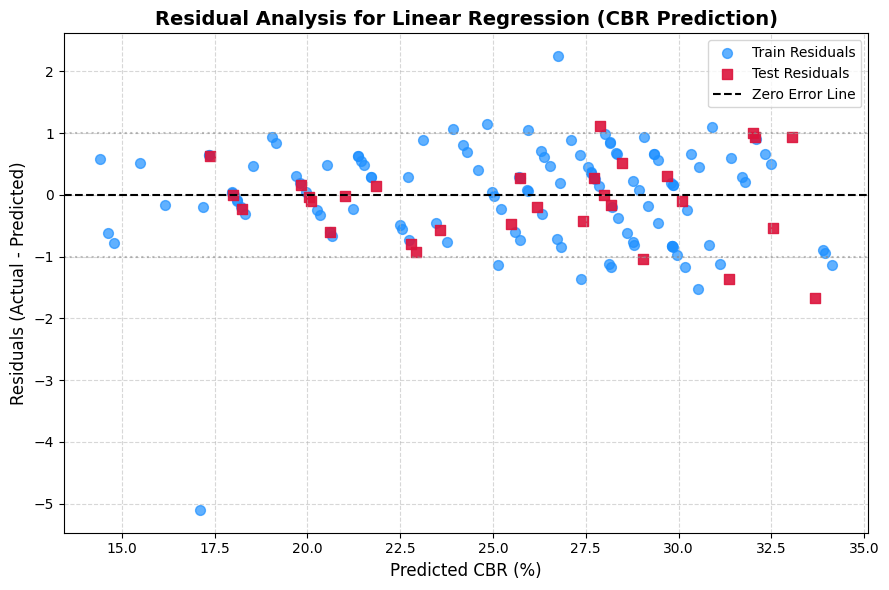

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Fit the Linear Regression pipeline on the training split
pipeline_lr.fit(X_train, y_train)

# 2. Make predictions for both train and test sets
y_train_pred = pipeline_lr.predict(X_train)
y_test_pred = pipeline_lr.predict(X_test)

# 3. Calculate residuals (Actual minus Predicted)
train_residuals = y_train - y_train_pred
test_residuals = y_test - y_test_pred

# 4. Create the residual plot
plt.figure(figsize=(9, 6))

# Plot training residuals
plt.scatter(y_train_pred, train_residuals, color='dodgerblue', alpha=0.7, s=50, label='Train Residuals')

# Plot test residuals (using squares to distinguish them)
plt.scatter(y_test_pred, test_residuals, color='crimson', alpha=0.9, marker='s', s=60, label='Test Residuals')

# Add a horizontal dashed line at zero (perfect prediction line)
plt.axhline(y=0, color='black', linestyle='--', linewidth=1.5, label='Zero Error Line')

# Labels and styling
plt.title('Residual Analysis for Linear Regression (CBR Prediction)', fontsize=14, fontweight='bold')
plt.xlabel('Predicted CBR (%)', fontsize=12)
plt.ylabel('Residuals (Actual - Predicted)', fontsize=12)
plt.axhline(y=1, color='gray', linestyle=':', alpha=0.5)
plt.axhline(y=-1, color='gray', linestyle=':', alpha=0.5)
plt.legend(frameon=True, facecolor='white')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [ ]:
# 1. Combine X_train and y_train back together to trace the samples
train_analysis_df = X_train.copy()
train_analysis_df['CBR_Actual'] = y_train
train_analysis_df['CBR_Predicted'] = y_train_pred
train_analysis_df['Residual'] = train_residuals

# 2. Filter for the outlier where the residual is less than -3
outlier_sample = train_analysis_df[train_analysis_df['Residual'] < -3]

print("--- Outlier Detection Report ---")
display(outlier_sample)

original_sample = soil_df.loc[87]

display(original_sample)

--- Outlier Detection Report ---


,G,S,F,LL,PL,OMC,MDD,CBR_Actual,CBR_Predicted,Residual
87,0.222041,0.126454,1.172399,1.449625,2.162822,2.50653,-0.842859,12.0,17.104346,-5.104346


,87
G,NaN
S,44.00
F,56.00
LL,46.00
PL,25.00
OMC,23.96
MDD,2.00
CBR,12.00


In [ ]:
# saving trained pipeline to a file
import joblib
joblib.dump(pipeline_lr, 'geostrengthAI pkl')
print('model pipeline successfully saved')

model pipeline successfully saved
